In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl


========== AXIAL ==========

First five rows:
   Tilt_Angle  FBG1_Wavelength  FBG2_Wavelength  Delta_FBG1  Delta_FBG2  \
0           0         1535.216         1547.351           0           0   
1          10         1535.222         1547.345           6          -6   
2          20         1535.227         1547.339          11         -12   
3          30         1535.232         1547.335          16         -16   
4          40         1535.237         1547.330          21         -21   

   Differential_Change  Average_Change  
0                  0.0             0.0  
1                 12.0             0.0  
2                 23.0            -0.5  
3                 32.0             0.0  
4                 42.0             0.0  

Dataset shape: (37, 7)
Observations: 37
Features: 6

Missing values:
Tilt_Angle             0
FBG1_Wavelength        0
FBG2_Wavelength        0
Delta_FBG1             0
Delta_FBG2             0
Differential_Change    0
Average_Change         0
dtype: int6

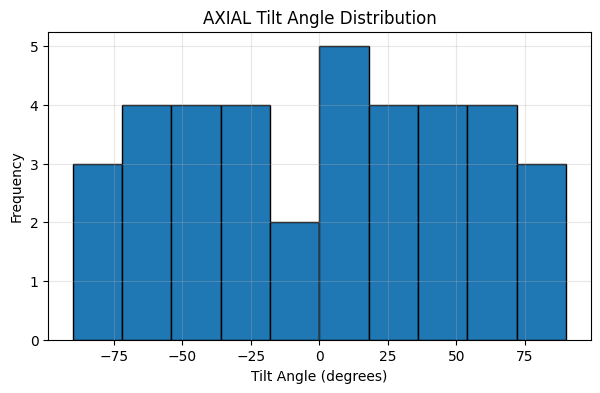


Repeated tilt angle measurements:
    Tilt_Angle  FBG1_Wavelength  FBG2_Wavelength
26         -80         1535.180         1547.385
28         -80         1535.180         1547.385
25         -70         1535.183         1547.384
29         -70         1535.182         1547.384
30         -60         1535.185         1547.380
24         -60         1535.185         1547.381
23         -50         1535.189         1547.377
31         -50         1535.189         1547.376
22         -40         1535.194         1547.372
32         -40         1535.193         1547.372
33         -30         1535.198         1547.367
21         -30         1535.199         1547.367
20         -20         1535.205         1547.361
34         -20         1535.203         1547.361
35         -10         1535.209         1547.355
19         -10         1535.210         1547.355
0            0         1535.216         1547.351
36           0         1535.214         1547.349
18           0         1535.216   

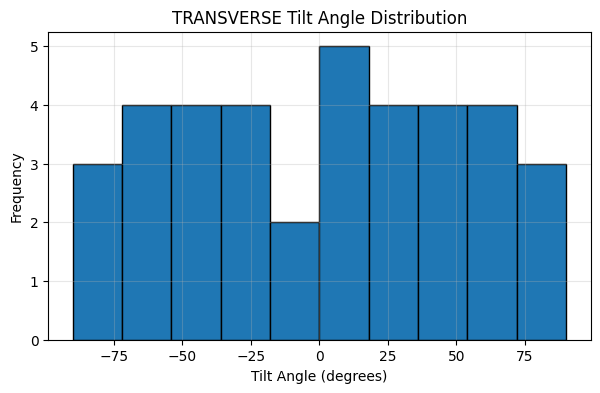


Repeated tilt angle measurements:
    Tilt_Angle  FBG1_Wavelength  FBG2_Wavelength
26         -80              554              669
28         -80              568              682
25         -70              528              646
29         -70              545              661
30         -60              513              632
24         -60              486              606
23         -50              439              566
31         -50              471              592
22         -40              391              517
32         -40              426              553
33         -30              373              499
21         -30              340              466
20         -20              300              429
34         -20              328              454
35         -10              280              413
19         -10              285              420
0            0              261              404
36           0              251              391
18           0              291   

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

file_name = "FBG biaxial tilt sensor.xlsx"

# Column names according to the assignment
columns = [
    "Tilt_Angle",
    "FBG1_Wavelength",
    "FBG2_Wavelength",
    "Delta_FBG1",
    "Delta_FBG2",
    "Differential_Change",
    "Average_Change"
]

# Read the first seven columns from each experimental sheet
axial = pd.read_excel(
    file_name,
    sheet_name="Experiment axial ",
    header=None,
    usecols=range(7),
    names=columns
)

transverse = pd.read_excel(
    file_name,
    sheet_name="Experiment transverse ",
    header=None,
    usecols=range(7),
    names=columns
)

def explore_data(data, name):

    print("\n==========", name, "==========")

    print("\nFirst five rows:")
    print(data.head())

    print("\nDataset shape:", data.shape)
    print("Observations:", len(data))
    print("Features:", len(data.columns) - 1)

    print("\nMissing values:")
    print(data.isnull().sum())

    print("\nDuplicate rows:", data.duplicated().sum())

    print("\nMean:")
    print(data.mean())

    print("\nMedian:")
    print(data.median())

    print("\nStandard deviation:")
    print(data.std())

    print("\nVariance:")
    print(data.var())

    print("\nMinimum:")
    print(data.min())

    print("\nMaximum:")
    print(data.max())

    print("\nComplete statistical summary:")
    print(data.describe())

    # Distribution of tilt angles
    plt.figure(figsize=(7, 4))
    plt.hist(data["Tilt_Angle"], bins=10,
             edgecolor="black")
    plt.xlabel("Tilt Angle (degrees)")
    plt.ylabel("Frequency")
    plt.title(name + " Tilt Angle Distribution")
    plt.grid(alpha=0.3)
    plt.show()

    # Show repeated tilt angles and sensor readings
    repeated = data[
        data.duplicated("Tilt_Angle", keep=False)
    ].sort_values("Tilt_Angle")

    print("\nRepeated tilt angle measurements:")
    print(repeated[
        ["Tilt_Angle", "FBG1_Wavelength",
         "FBG2_Wavelength"]
    ])

# Analyze both experimental datasets separately
explore_data(axial, "AXIAL")
explore_data(transverse, "TRANSVERSE")


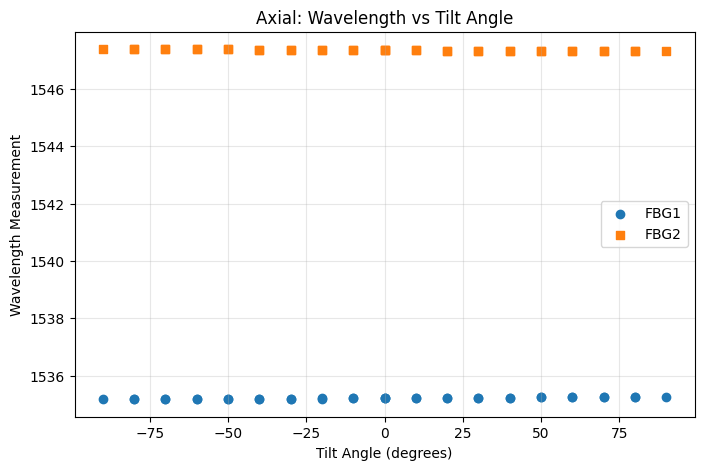

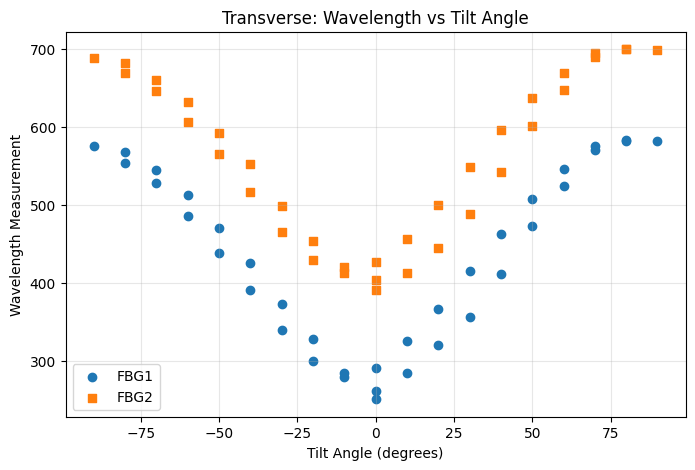

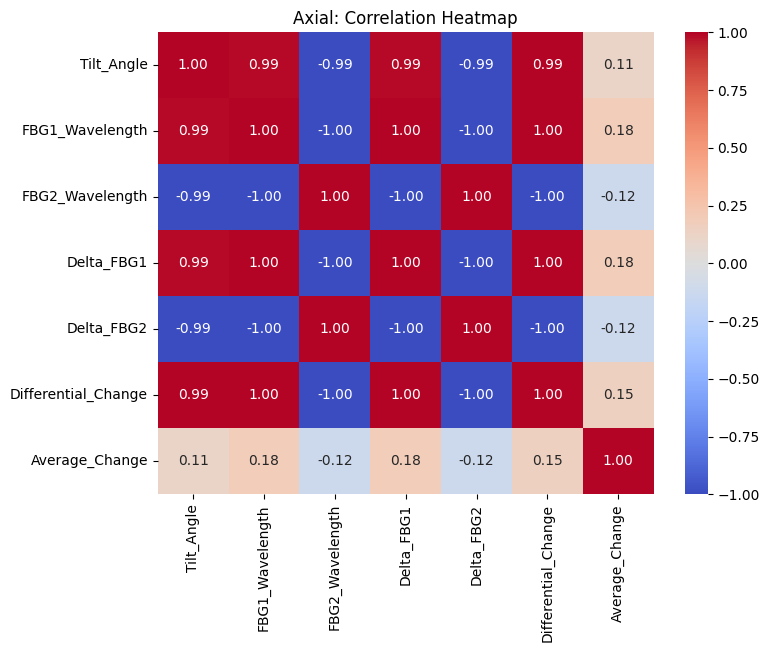

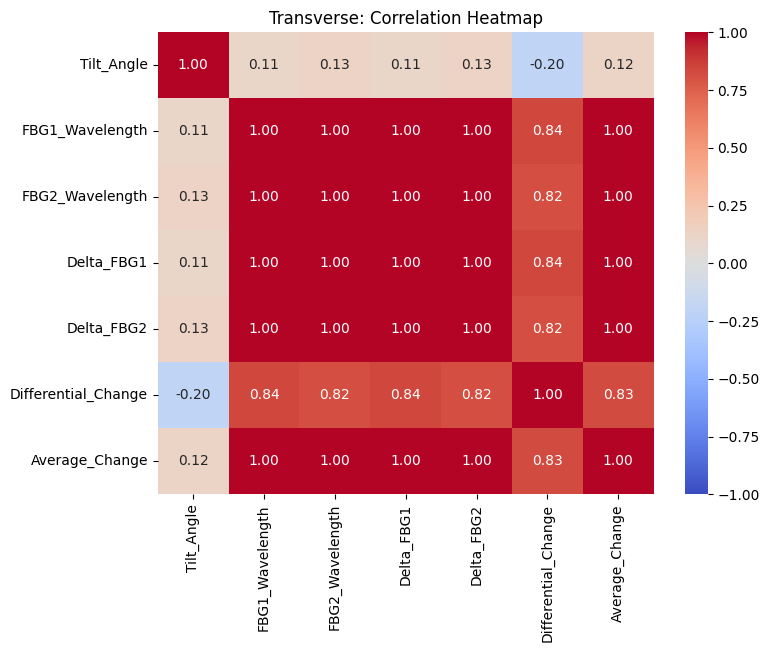

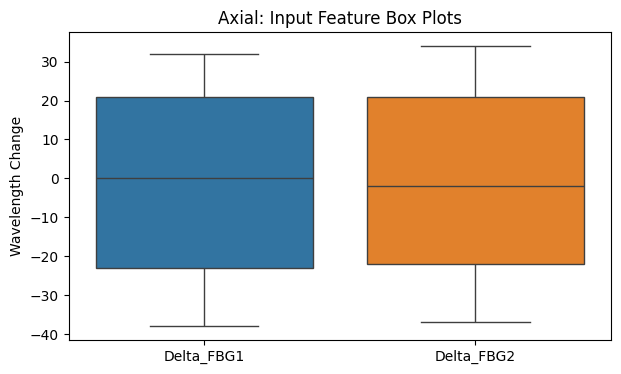

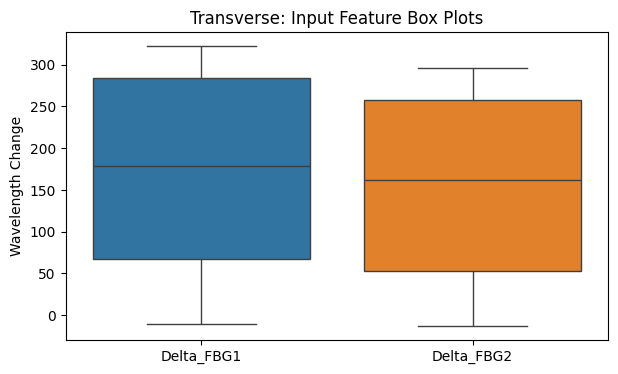

Axial Original training data:
   Delta_FBG1  Delta_FBG2
0           0           0
1           6          -6
3          16         -16
4          21         -21
5          26         -26

After StandardScaler:
   Delta_FBG1  Delta_FBG2
0   -0.168826    0.224513
1    0.084413   -0.028629
2    0.506479   -0.450533
3    0.717512   -0.661484
4    0.928545   -0.872436

After MinMaxScaler:
   Delta_FBG1  Delta_FBG2
0    0.515152    0.528571
1    0.606061    0.442857
2    0.757576    0.300000
3    0.833333    0.228571
4    0.909091    0.157143


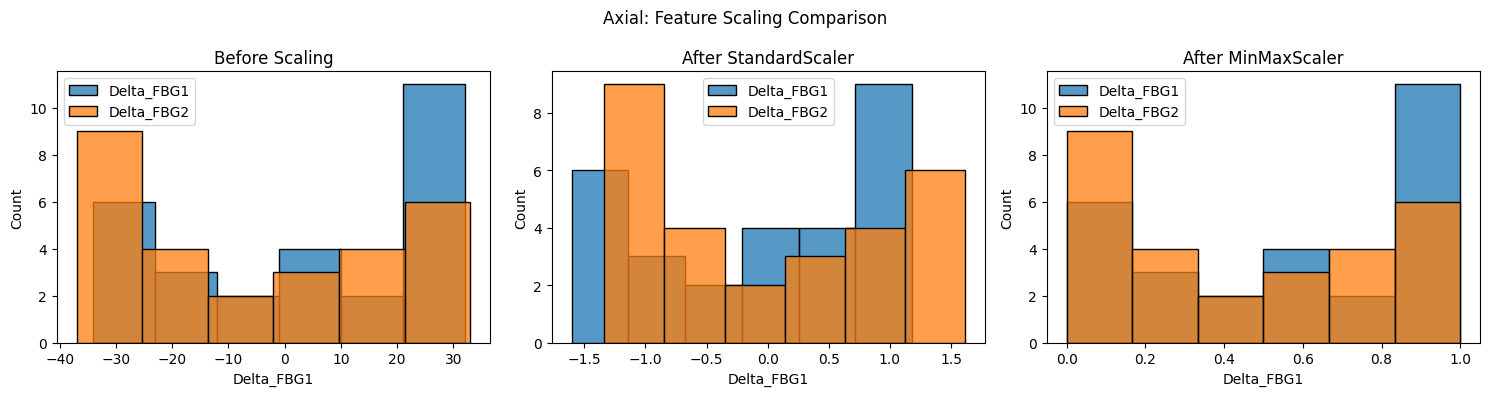

Transverse Original training data:
   Delta_FBG1  Delta_FBG2
0           0           0
1          23           9
3          96          84
4         151         138
5         212         197

After StandardScaler:
   Delta_FBG1  Delta_FBG2
0   -1.650539   -1.577663
1   -1.438797   -1.490189
2   -0.766745   -0.761235
3   -0.260404   -0.236389
4    0.301174    0.337054

After MinMaxScaler:
   Delta_FBG1  Delta_FBG2
0    0.030120    0.042071
1    0.099398    0.071197
2    0.319277    0.313916
3    0.484940    0.488673
4    0.668675    0.679612


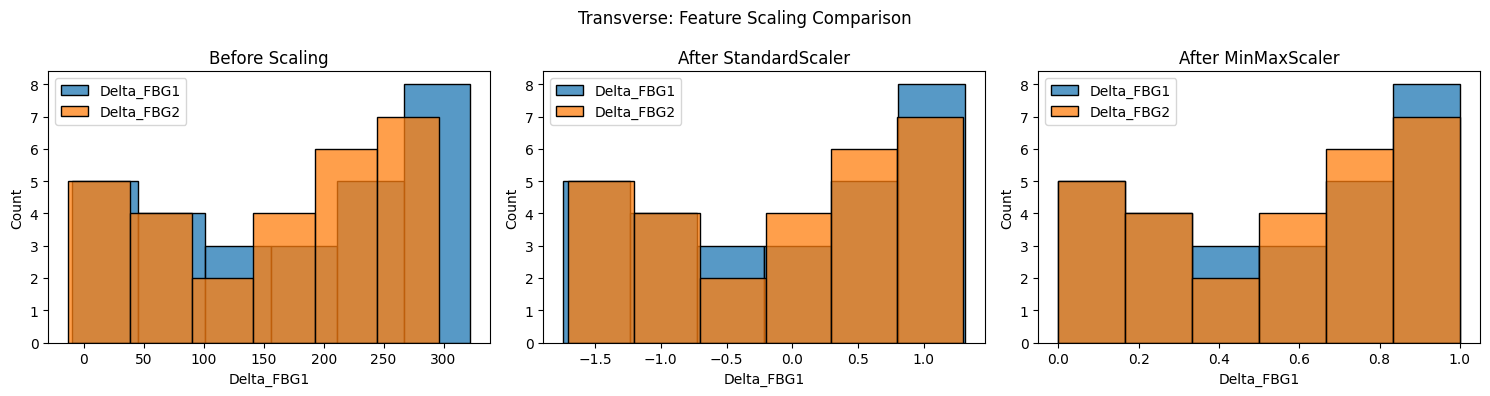

In [ ]:
## TASK-2

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler


# Plot FBG1 and FBG2 wavelength responses

def plot_wavelengths(data, name):
    plt.figure(figsize=(8, 5))
    plt.scatter(data["Tilt_Angle"], data["FBG1_Wavelength"],
                label="FBG1", marker="o")

    plt.scatter(data["Tilt_Angle"], data["FBG2_Wavelength"],
                label="FBG2", marker="s")

    plt.xlabel("Tilt Angle (degrees)")
    plt.ylabel("Wavelength Measurement")
    plt.title(name + ": Wavelength vs Tilt Angle")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
plot_wavelengths(axial, "Axial")
plot_wavelengths(transverse, "Transverse")


# Correlation heatmaps for both datasets

def plot_correlation(data, name):
    plt.figure(figsize=(8, 6))
    sns.heatmap(data.corr(numeric_only=True),
                annot=True, cmap="coolwarm",
                fmt=".2f", vmin=-1, vmax=1)

    plt.title(name + ": Correlation Heatmap")
    plt.show()
plot_correlation(axial, "Axial")
plot_correlation(transverse, "Transverse")

# Check possible outliers in input features

features = ["Delta_FBG1", "Delta_FBG2"]

def plot_boxplots(data, name):
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=data[features])
    plt.title(name + ": Input Feature Box Plots")
    plt.ylabel("Wavelength Change")
    plt.show()

plot_boxplots(axial, "Axial")
plot_boxplots(transverse, "Transverse")


# Scale input features without data leakage

features = ["Delta_FBG1", "Delta_FBG2"]

def compare_scaling(data, name):
    X = data[features]
    groups = data["Tilt_Angle"]

    splitter = GroupShuffleSplit(
        n_splits=1, test_size=0.25, random_state=42
    )

    train_idx, test_idx = next(
        splitter.split(X, groups=groups)
    )

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    # Fit scalers only on training data
    standard_scaler = StandardScaler()
    minmax_scaler = MinMaxScaler()

    X_standard_train = standard_scaler.fit_transform(X_train)
    X_standard_test = standard_scaler.transform(X_test)

    X_minmax_train = minmax_scaler.fit_transform(X_train)
    X_minmax_test = minmax_scaler.transform(X_test)

    standard_df = pd.DataFrame(
        X_standard_train, columns=features
    )

    minmax_df = pd.DataFrame(
        X_minmax_train, columns=features
    )

    print(name, "Original training data:")
    print(X_train.head())

    print("\nAfter StandardScaler:")
    print(standard_df.head())

    print("\nAfter MinMaxScaler:")
    print(minmax_df.head())

    # Compare distributions before and after scaling
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for feature in features:
        sns.histplot(
            X_train[feature], ax=axes[0],
            label=feature, kde=False
        )

        sns.histplot(
            standard_df[feature], ax=axes[1],
            label=feature, kde=False
        )

        sns.histplot(
            minmax_df[feature], ax=axes[2],
            label=feature, kde=False
        )
    axes[0].set_title("Before Scaling")
    axes[1].set_title("After StandardScaler")
    axes[2].set_title("After MinMaxScaler")

    for ax in axes:
        ax.legend()

    plt.suptitle(name + ": Feature Scaling Comparison")
    plt.tight_layout()
    plt.show()

    return X_train, X_test, X_standard_train, X_standard_test, \
           X_minmax_train, X_minmax_test
axial_scaling = compare_scaling(axial, "Axial")
transverse_scaling = compare_scaling(transverse, "Transverse")


 AXIAL Feature Correlation
  Configuration             Feature  Pearson_Correlation
  F1_Individual          Delta_FBG1               0.9917
  F1_Individual          Delta_FBG2              -0.9939
F2_Differential Differential_Change               0.9932
     F3_Average      Average_Change               0.1135
    F4_Diff_Avg Differential_Change               0.9932
    F4_Diff_Avg      Average_Change               0.1135

Feature Configuration Comparison
  Configuration  Mean_Absolute_Correlation
F2_Differential                     0.9932
  F1_Individual                     0.9928
    F4_Diff_Avg                     0.5534
     F3_Average                     0.1135

 TRANSVERSE Feature Correlation
  Configuration             Feature  Pearson_Correlation
  F1_Individual          Delta_FBG1               0.1082
  F1_Individual          Delta_FBG2               0.1288
F2_Differential Differential_Change              -0.2007
     F3_Average      Average_Change               0.1183
    F4

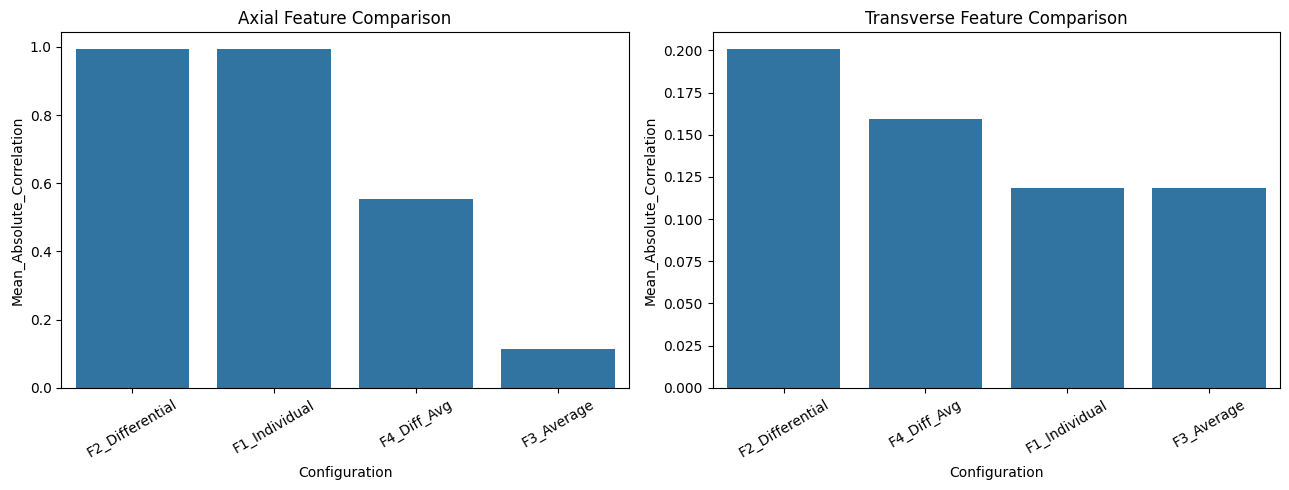


Best candidate configurations:
Axial: F2_Differential
Transverse: F2_Differential


In [ ]:
## TASK-3

import numpy as np

# Create differential and average features
for data in [axial, transverse]:
    data["Differential_Change"] = data["Delta_FBG1"] - data["Delta_FBG2"]
    data["Average_Change"] = (data["Delta_FBG1"] + data["Delta_FBG2"]) / 2

# Define feature configurations
feature_sets = {
    "F1_Individual": ["Delta_FBG1", "Delta_FBG2"],
    "F2_Differential": ["Differential_Change"],
    "F3_Average": ["Average_Change"],
    "F4_Diff_Avg": ["Differential_Change", "Average_Change"]
}

# Calculate Pearson correlation and compare features
def analyze_features(data, name):
    correlation_rows = []
    comparison_rows = []

    for config, features in feature_sets.items():
        correlations = []

        for feature in features:
            corr = data[feature].corr(data["Tilt_Angle"])
            correlations.append(corr)
            correlation_rows.append({
                "Configuration": config,
                "Feature": feature,
                "Pearson_Correlation": corr
            })

        valid = [abs(c) for c in correlations if pd.notna(c)]
        mean_corr = np.mean(valid) if valid else np.nan

        comparison_rows.append({
            "Configuration": config,
            "Mean_Absolute_Correlation": mean_corr
        })

    correlation_table = pd.DataFrame(correlation_rows)
    comparison_table = pd.DataFrame(comparison_rows).sort_values(
        "Mean_Absolute_Correlation", ascending=False, na_position="last"
    )

    print("\n", name, "Feature Correlation")
    print(correlation_table.round(4).to_string(index=False))
    print("\nFeature Configuration Comparison")
    print(comparison_table.round(4).to_string(index=False))

    return correlation_table, comparison_table

# Analyze axial and transverse datasets
axial_corr, axial_comparison = analyze_features(axial, "AXIAL")
transverse_corr, transverse_comparison = analyze_features(transverse, "TRANSVERSE")

# Plot feature configuration comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=axial_comparison, x="Configuration",
            y="Mean_Absolute_Correlation", ax=axes[0])
axes[0].set_title("Axial Feature Comparison")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=transverse_comparison, x="Configuration",
            y="Mean_Absolute_Correlation", ax=axes[1])
axes[1].set_title("Transverse Feature Comparison")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# Display the best candidate configurations
print("\nBest candidate configurations:")
print("Axial:", axial_comparison.iloc[0]["Configuration"])
print("Transverse:", transverse_comparison.iloc[0]["Configuration"])



AXIAL REGRESSION RESULTS
                           Model    MAE      MSE    RMSE     R2  Training_Time_s
        Simple Linear Regression 6.1959  61.4621  7.8398 0.9616           0.0325
                Ridge Regression 6.5528  73.3143  8.5624 0.9542           0.0216
          Elastic Net Regression 6.7079  74.7491  8.6458 0.9534           0.0072
Polynomial Regression (Degree 3) 4.9495  95.9466  9.7952 0.9401           0.0186
Polynomial Regression (Degree 2) 7.1215 104.2313 10.2094 0.9350           0.0179
                Lasso Regression 7.7617 106.3649 10.3133 0.9336           0.0133
      Multiple Linear Regression 7.9209 111.9892 10.5825 0.9301           0.0150


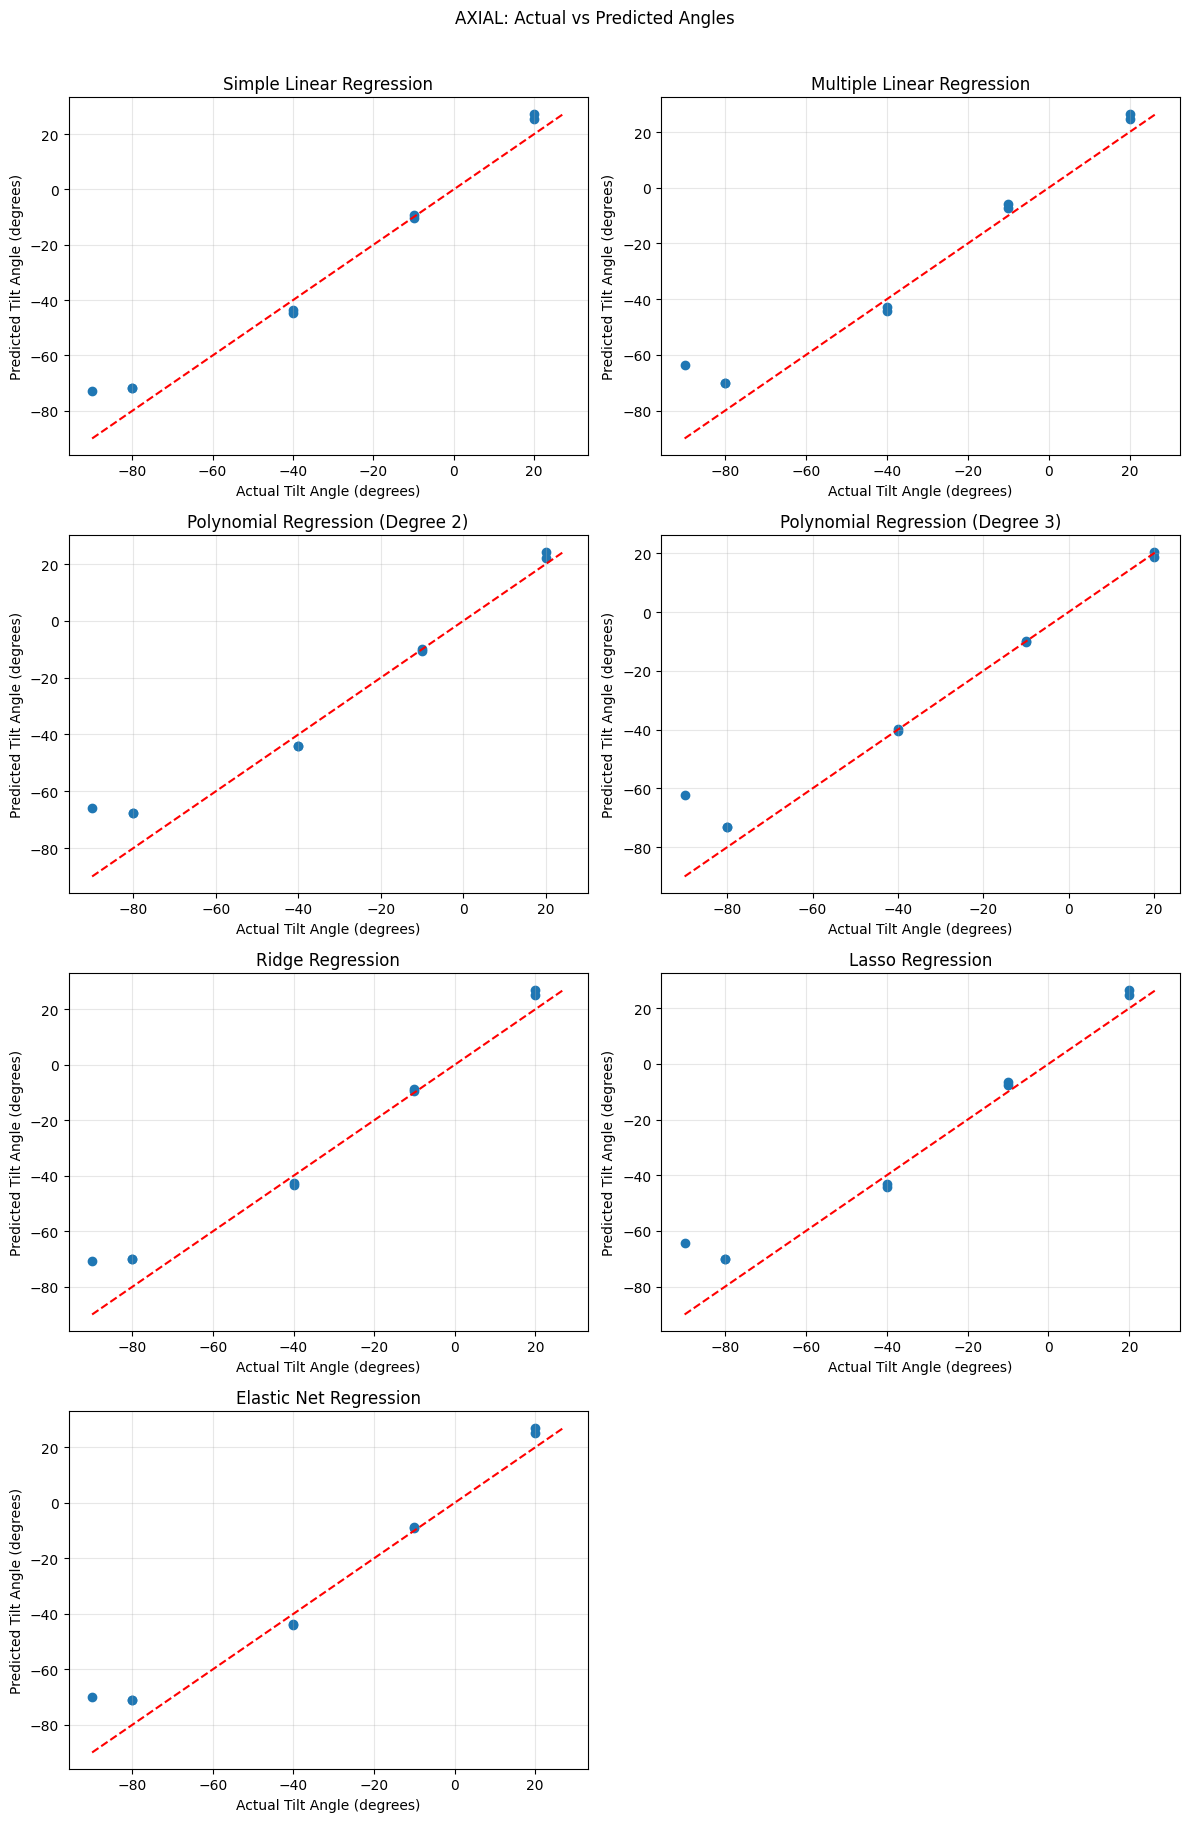


TRANSVERSE REGRESSION RESULTS
                           Model     MAE       MSE    RMSE      R2  Training_Time_s
Polynomial Regression (Degree 3) 22.6941  631.5065 25.1298  0.6059           0.0081
Polynomial Regression (Degree 2) 29.4222 1179.3981 34.3424  0.2640           0.0089
      Multiple Linear Regression 46.2503 3277.5418 57.2498 -1.0453           0.0066
                Lasso Regression 46.4194 3302.3751 57.4663 -1.0608           0.0119
        Simple Linear Regression 49.7249 3733.7318 61.1043 -1.3300           0.0303
          Elastic Net Regression 53.6870 4689.5932 68.4806 -1.9265           0.0091
                Ridge Regression 54.4342 4911.8789 70.0848 -2.0652           0.0085


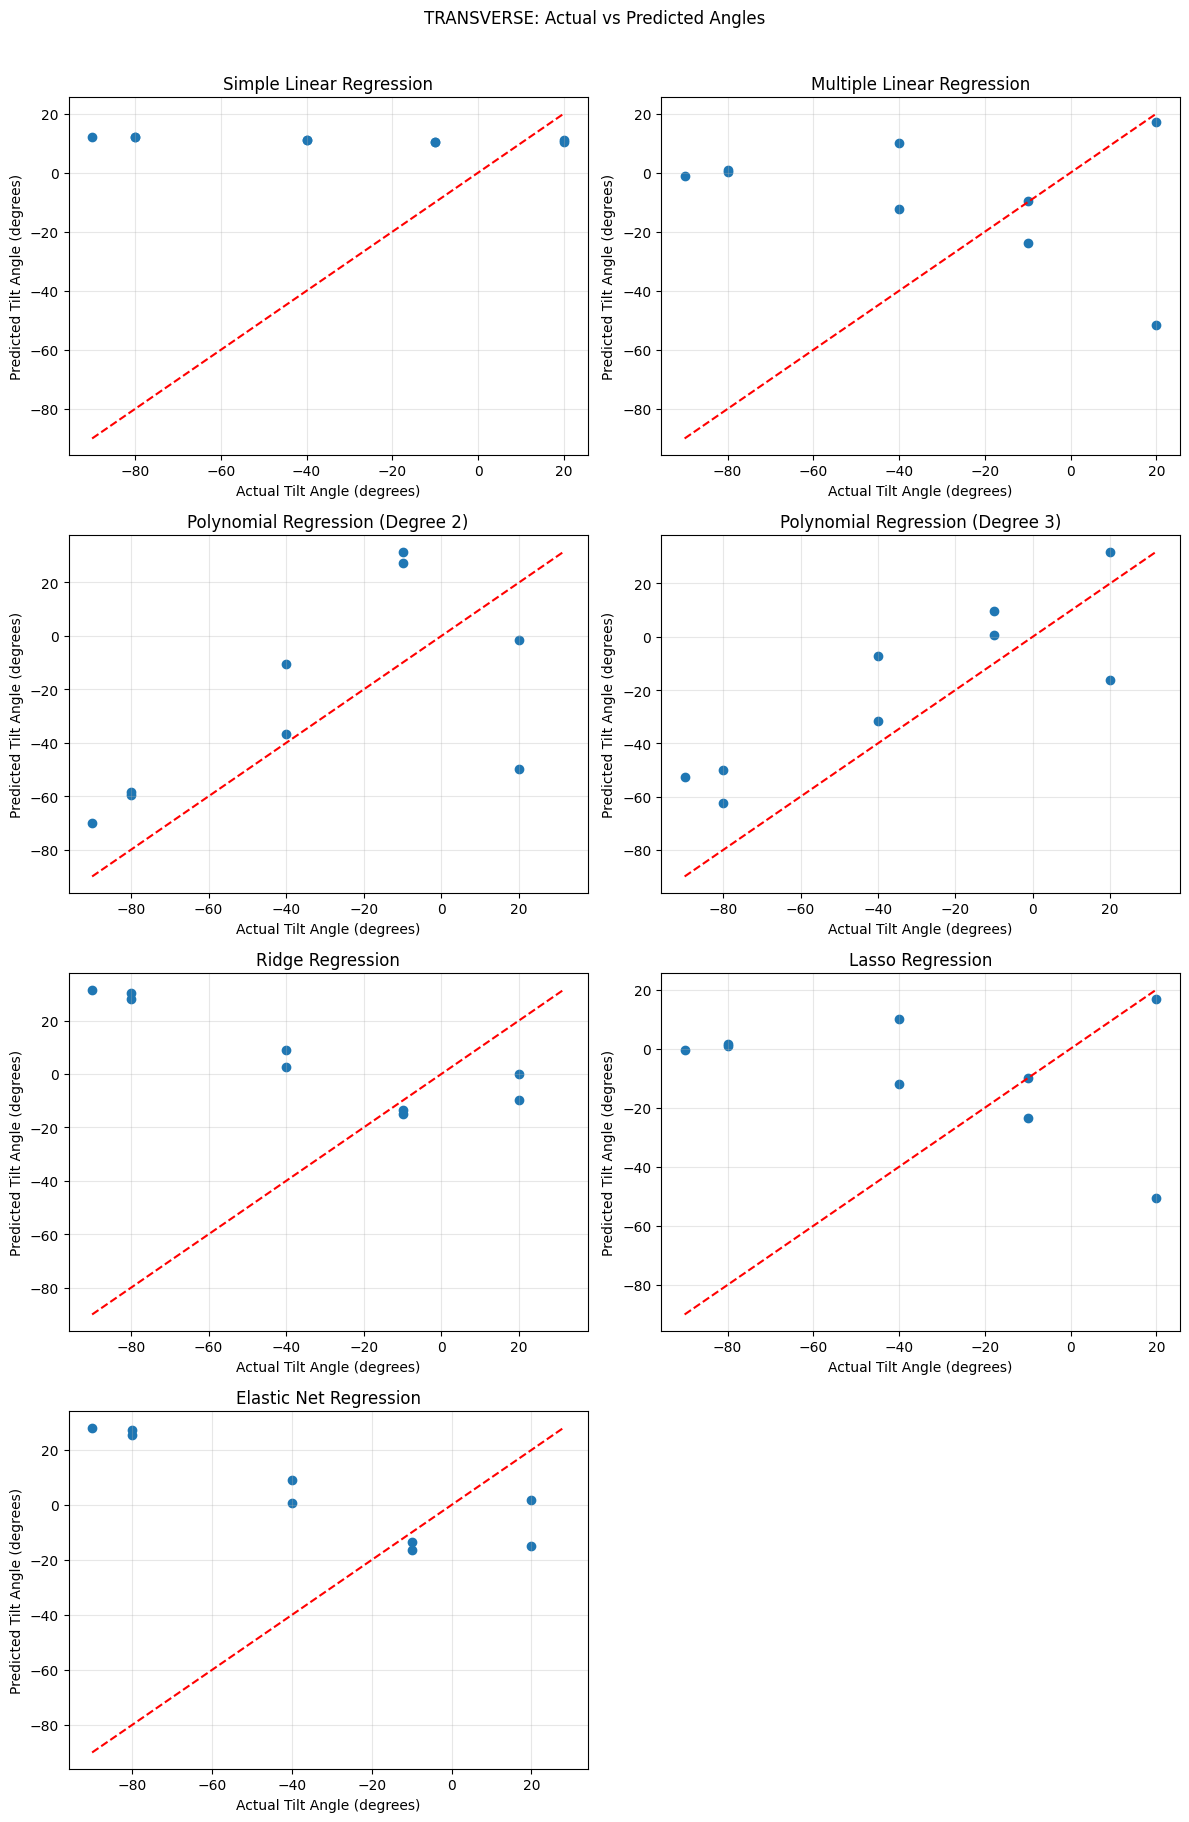


Best traditional regression models by test RMSE:
Axial: Simple Linear Regression
Transverse: Polynomial Regression (Degree 3)


In [ ]:
## TASK-4
import time
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare regression models
models = {
    "Simple Linear Regression": make_pipeline(
        StandardScaler(), LinearRegression()
    ),
    "Multiple Linear Regression": LinearRegression(),
    "Polynomial Regression (Degree 2)": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),
    "Polynomial Regression (Degree 3)": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(), Ridge(alpha=1.0)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(), Lasso(alpha=0.01, max_iter=10000)
    ),
    "Elastic Net Regression": make_pipeline(
        StandardScaler(),
        ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000)
    )
}

def run_regression(data, name):
    results = []
    predictions = {}

    # Simple linear regression uses the differential feature.
    # Other models use the two individual wavelength changes.
    X_simple = data[["Differential_Change"]]
    X_multiple = data[["Delta_FBG1", "Delta_FBG2"]]
    y = data["Tilt_Angle"]
    groups = data["Tilt_Angle"]

    splitter = GroupShuffleSplit(
        n_splits=1, test_size=0.25, random_state=42
    )
    train_idx, test_idx = next(
        splitter.split(X_multiple, y, groups=groups)
    )

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    for model_name, model in models.items():
        if model_name == "Simple Linear Regression":
            X_train = X_simple.iloc[train_idx]
            X_test = X_simple.iloc[test_idx]
        else:
            X_train = X_multiple.iloc[train_idx]
            X_test = X_multiple.iloc[test_idx]

        start = time.time()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        elapsed = time.time() - start

        results.append({
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, y_pred),
            "MSE": mean_squared_error(y_test, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
            "R2": r2_score(y_test, y_pred),
            "Training_Time_s": elapsed
        })

        predictions[model_name] = y_pred

    result_df = pd.DataFrame(results).sort_values("RMSE")

    print("\n" + "=" * 60)
    print(name, "REGRESSION RESULTS")
    print("=" * 60)
    print(result_df.round(4).to_string(index=False))

    # Actual versus predicted plots for each model
    fig, axes = plt.subplots(4, 2, figsize=(12, 18))
    axes = axes.flatten()

    for i, (model_name, y_pred) in enumerate(predictions.items()):
        axes[i].scatter(y_test, y_pred)
        low = min(y_test.min(), y_pred.min())
        high = max(y_test.max(), y_pred.max())

        axes[i].plot([low, high], [low, high], "r--")
        axes[i].set_title(model_name)
        axes[i].set_xlabel("Actual Tilt Angle (degrees)")
        axes[i].set_ylabel("Predicted Tilt Angle (degrees)")
        axes[i].grid(alpha=0.3)

    axes[-1].axis("off")
    plt.suptitle(name + ": Actual vs Predicted Angles", y=1.01)
    plt.tight_layout()
    plt.show()

    return result_df, predictions, y_test

# Run models separately for both datasets
axial_results, axial_predictions, axial_y_test = run_regression(
    axial, "AXIAL"
)

transverse_results, transverse_predictions, transverse_y_test = run_regression(
    transverse, "TRANSVERSE"
)

# Display the best model by test RMSE
print("\nBest traditional regression models by test RMSE:")
print("Axial:", axial_results.iloc[0]["Model"])
print("Transverse:", transverse_results.iloc[0]["Model"])


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(



AXIAL ML REGRESSION RESULTS
                 Model     MAE       MSE    RMSE      R2  Training_Time_s
            GPR Matern  6.5099   84.6731  9.2018  0.9472           0.1365
 Gradient Boosting 0.1  8.7504  102.8796 10.1430  0.9358           0.5361
     Random Forest 100  8.0222  107.3978 10.3633  0.9330           0.2678
                 KNN 3  7.7778  107.4074 10.3638  0.9330           0.0118
      Random Forest 50  8.5333  116.3289 10.7856  0.9274           0.1357
 Decision Tree Depth 5 11.1111  133.3333 11.5470  0.9168           0.0058
            SVR Linear  7.7987  153.9192 12.4064  0.9039           0.0115
                 KNN 5  9.3333  167.1111 12.9271  0.8957           0.0093
 Decision Tree Depth 3 13.7778  199.7778 14.1343  0.8753           0.0051
                 KNN 7 11.1111  267.5737 16.3577  0.8330           0.0095
 Decision Tree Depth 2 17.9012  415.2263 20.3771  0.7409           0.0056
Gradient Boosting 0.01 21.4275  740.6753 27.2154  0.5378           0.1703
         

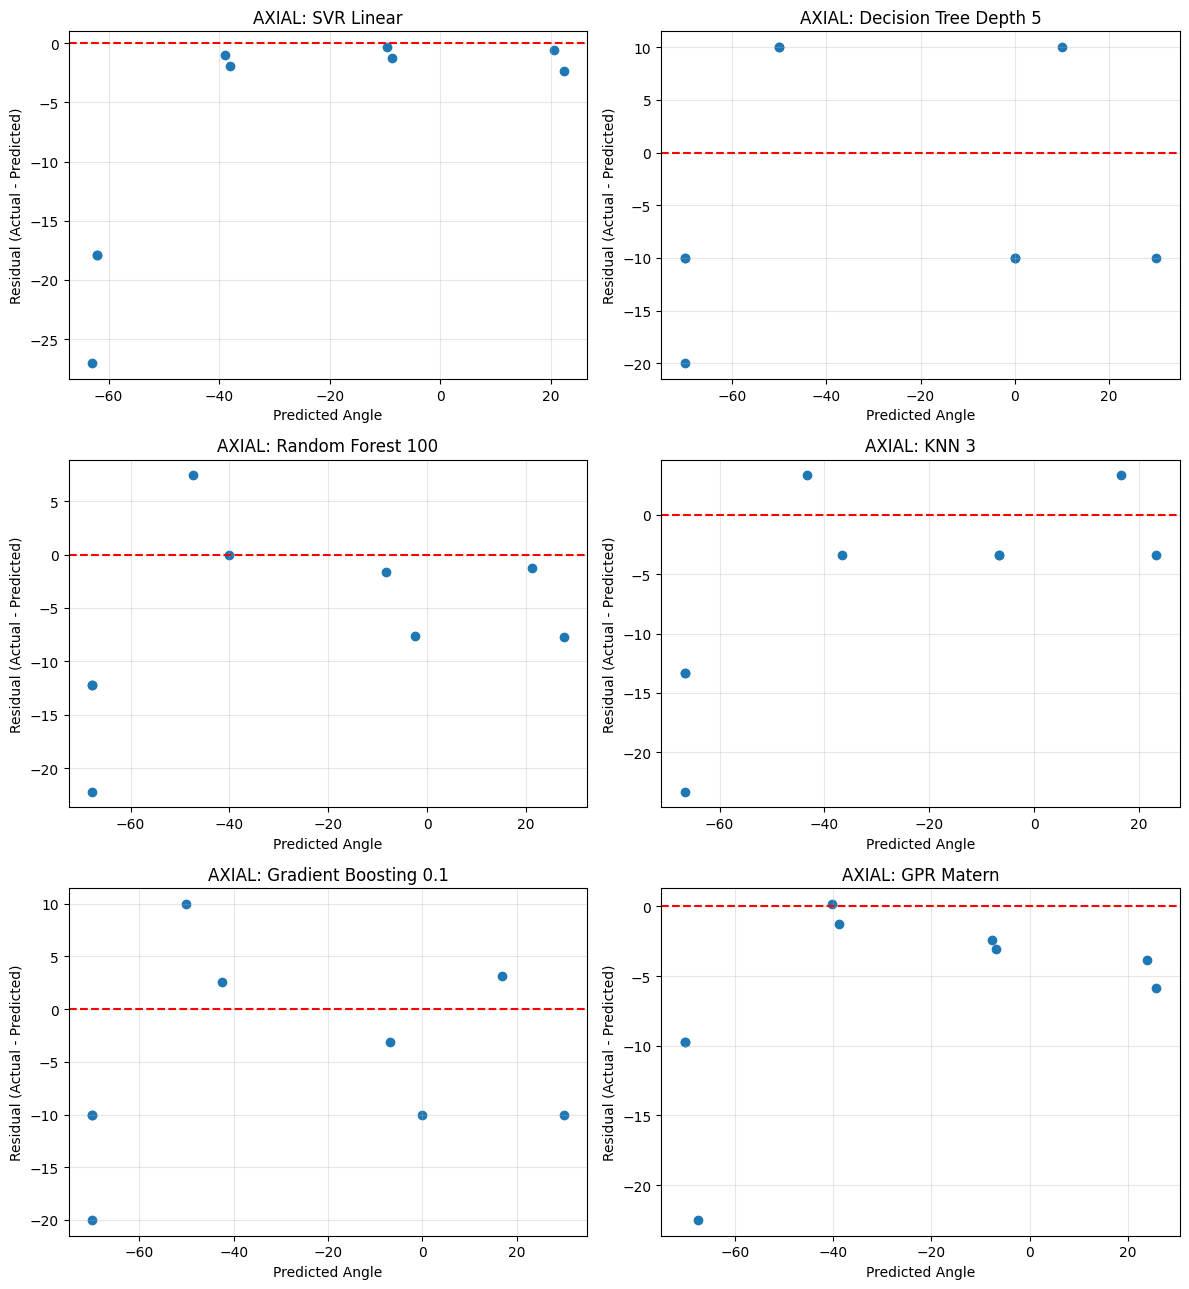

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(



TRANSVERSE ML REGRESSION RESULTS
                 Model     MAE       MSE    RMSE      R2  Training_Time_s
               GPR RBF 49.4841 3674.1638 60.6149 -1.2928           0.0134
            GPR Matern 49.4841 3674.1638 60.6149 -1.2928           0.0267
               SVR RBF 52.6333 4279.0843 65.4147 -1.6703           0.0137
Gradient Boosting 0.01 58.8287 6088.2443 78.0272 -2.7993           0.1720
                 KNN 7 58.4127 6153.7415 78.4458 -2.8402           0.0154
      Random Forest 50 64.6222 7224.5067 84.9971 -3.5084           0.2469
     Random Forest 100 65.0333 7301.1878 85.4470 -3.5562           0.2901
                 KNN 5 64.4444 7476.4444 86.4664 -3.6656           0.0076
                 KNN 3 67.0370 7707.4074 87.7918 -3.8097           0.0116
            SVR Linear 66.5607 7746.3249 88.0132 -3.8340           0.0387
 Decision Tree Depth 3 64.1975 7932.3045 89.0635 -3.9501           0.0040
 Decision Tree Depth 5 64.2857 7934.4671 89.0756 -3.9514           0.0039
 Dec

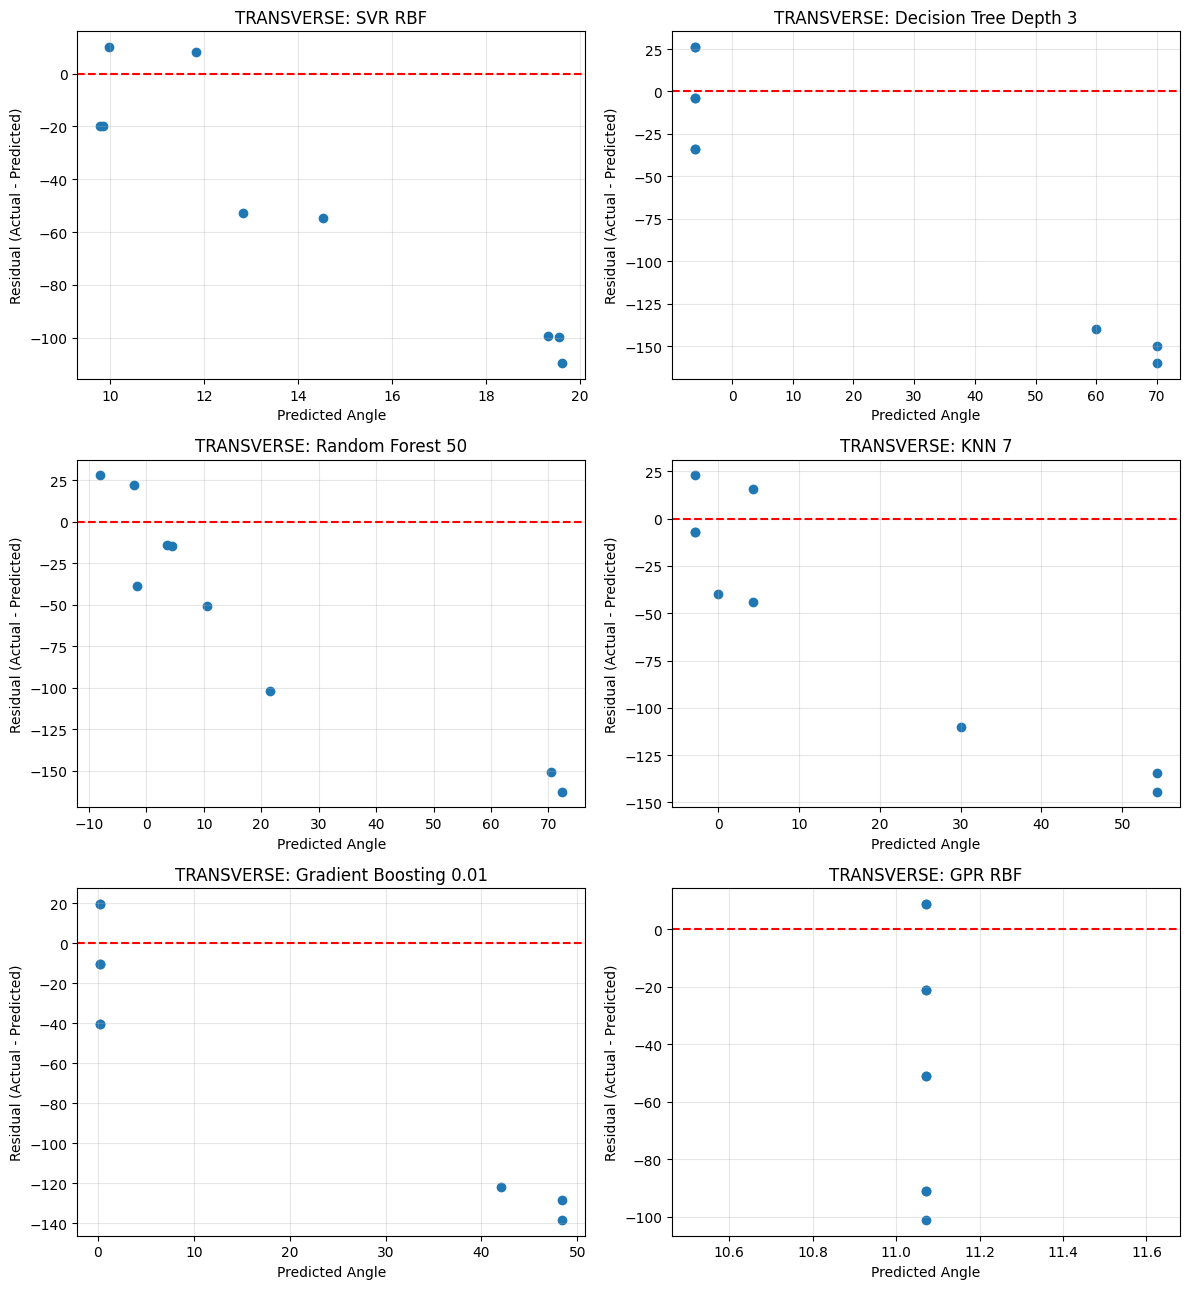


Best conventional ML model by test RMSE:
Axial: GPR Matern
Transverse: GPR RBF


In [ ]:
## TASK-5
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern

# Define models and hyperparameters
models = {
    "SVR Linear": make_pipeline(
        StandardScaler(), SVR(kernel="linear")
    ),
    "SVR RBF": make_pipeline(
        StandardScaler(), SVR(kernel="rbf")
    ),
    "Decision Tree Depth 2": DecisionTreeRegressor(
        max_depth=2, random_state=42
    ),
    "Decision Tree Depth 3": DecisionTreeRegressor(
        max_depth=3, random_state=42
    ),
    "Decision Tree Depth 5": DecisionTreeRegressor(
        max_depth=5, random_state=42
    ),
    "Random Forest 50": RandomForestRegressor(
        n_estimators=50, random_state=42
    ),
    "Random Forest 100": RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    "KNN 3": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=3)
    ),
    "KNN 5": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=5)
    ),
    "KNN 7": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=7)
    ),
    "Gradient Boosting 0.01": GradientBoostingRegressor(
        learning_rate=0.01, random_state=42
    ),
    "Gradient Boosting 0.1": GradientBoostingRegressor(
        learning_rate=0.1, random_state=42
    ),
    "GPR RBF": make_pipeline(
        StandardScaler(),
        GaussianProcessRegressor(
            kernel=RBF(), normalize_y=True, random_state=42
        )
    ),
    "GPR Matern": make_pipeline(
        StandardScaler(),
        GaussianProcessRegressor(
            kernel=Matern(), normalize_y=True, random_state=42
        )
    )
}

def run_ml_models(data, name):
    X = data[["Delta_FBG1", "Delta_FBG2"]]
    y = data["Tilt_Angle"]
    groups = data["Tilt_Angle"]

    splitter = GroupShuffleSplit(
        n_splits=1, test_size=0.25, random_state=42
    )
    train_idx, test_idx = next(
        splitter.split(X, y, groups=groups)
    )

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    results = []
    predictions = {}

    for model_name, model in models.items():
        start = time.time()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        elapsed = time.time() - start

        results.append({
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, y_pred),
            "MSE": mean_squared_error(y_test, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
            "R2": r2_score(y_test, y_pred),
            "Training_Time_s": elapsed
        })

        predictions[model_name] = y_pred

    results_df = pd.DataFrame(results).sort_values("RMSE")

    print("\n", "=" * 65)
    print(name, "ML REGRESSION RESULTS")
    print("=" * 65)
    print(results_df.round(4).to_string(index=False))

    # Compare hyperparameter settings
    print("\nHyperparameter comparison:")
    for family in [
        "SVR", "Decision Tree", "Random Forest",
        "KNN", "Gradient Boosting", "GPR"
    ]:
        print("\n" + family)
        print(
            results_df[
                results_df["Model"].str.startswith(family)
            ][["Model", "MAE", "RMSE", "R2"]]
            .round(4).to_string(index=False)
        )

    # Residual plots for the best model in each model family
    families = [
        "SVR", "Decision Tree", "Random Forest",
        "KNN", "Gradient Boosting", "GPR"
    ]

    fig, axes = plt.subplots(3, 2, figsize=(12, 13))
    axes = axes.flatten()

    for i, family in enumerate(families):
        family_results = results_df[
            results_df["Model"].str.startswith(family)
        ]
        best_name = family_results.iloc[0]["Model"]
        y_pred = predictions[best_name]
        residuals = y_test.to_numpy() - y_pred

        axes[i].scatter(y_pred, residuals)
        axes[i].axhline(0, linestyle="--", color="red")
        axes[i].set_title(name + ": " + best_name)
        axes[i].set_xlabel("Predicted Angle")
        axes[i].set_ylabel("Residual (Actual - Predicted)")
        axes[i].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return results_df, predictions, y_test

# Run all six model families on each dataset
axial_ml_results, axial_ml_predictions, axial_ml_y_test = run_ml_models(
    axial, "AXIAL"
)

transverse_ml_results, transverse_ml_predictions, transverse_ml_y_test = run_ml_models(
    transverse, "TRANSVERSE"
)

print("\nBest conventional ML model by test RMSE:")
print("Axial:", axial_ml_results.iloc[0]["Model"])
print("Transverse:", transverse_ml_results.iloc[0]["Model"])


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/_gpr.py:660: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/_gpr.py:660: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)



 AXIAL FIVE-FOLD GROUPED CV RESULTS
                     Model     MAE      MSE    RMSE     R2  Training_Time_s
          Gaussian Process  2.7833  11.2618  3.3559 0.9957           0.6462
  Simple Linear Regression  5.0960  39.3909  6.2762 0.9851           4.1390
          Ridge Regression  5.0572  42.4876  6.5182 0.9839           0.4362
               Elastic Net  5.1233  44.0748  6.6389 0.9833           0.6660
          Lasso Regression  5.2209  44.7488  6.6895 0.9831           0.4163
     Polynomial Regression  4.4589  45.2782  6.7289 0.9829           0.3685
Multiple Linear Regression  5.3583  46.5443  6.8223 0.9824           0.1633
                SVR Linear  4.9562  56.6926  7.5295 0.9786           0.4514
             Random Forest  7.0595  66.0054  8.1244 0.9750           4.8846
                       KNN  6.5766  67.1111  8.1921 0.9746           0.4445
         Gradient Boosting  8.4213  84.1615  9.1740 0.9682           2.2033
             Decision Tree 10.2703 108.1081 10.3975

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The opti


 TRANSVERSE FIVE-FOLD GROUPED CV RESULTS
                     Model     MAE       MSE    RMSE      R2  Training_Time_s
     Polynomial Regression 20.7143  658.4567 25.6604  0.7509           0.2018
          Lasso Regression 38.3969 2049.2586 45.2687  0.2247           0.3341
Multiple Linear Regression 39.0920 2110.9139 45.9447  0.2014           0.0884
               Elastic Net 40.5081 2355.7023 48.5356  0.1088           0.4744
          Ridge Regression 42.9545 2593.3665 50.9251  0.0189           0.2334
          Gaussian Process 43.9459 2664.7450 51.6212 -0.0081           0.6654
                   SVR RBF 44.2196 2671.8586 51.6900 -0.0108           0.4455
                SVR Linear 44.1638 2674.0957 51.7117 -0.0117           0.2426
  Simple Linear Regression 45.3731 2690.4178 51.8692 -0.0178           0.1606
         Gradient Boosting 45.5016 3473.9077 58.9399 -0.3143           2.7098
                       KNN 50.1081 3504.7568 59.2010 -0.3259           0.2468
             Random Fo

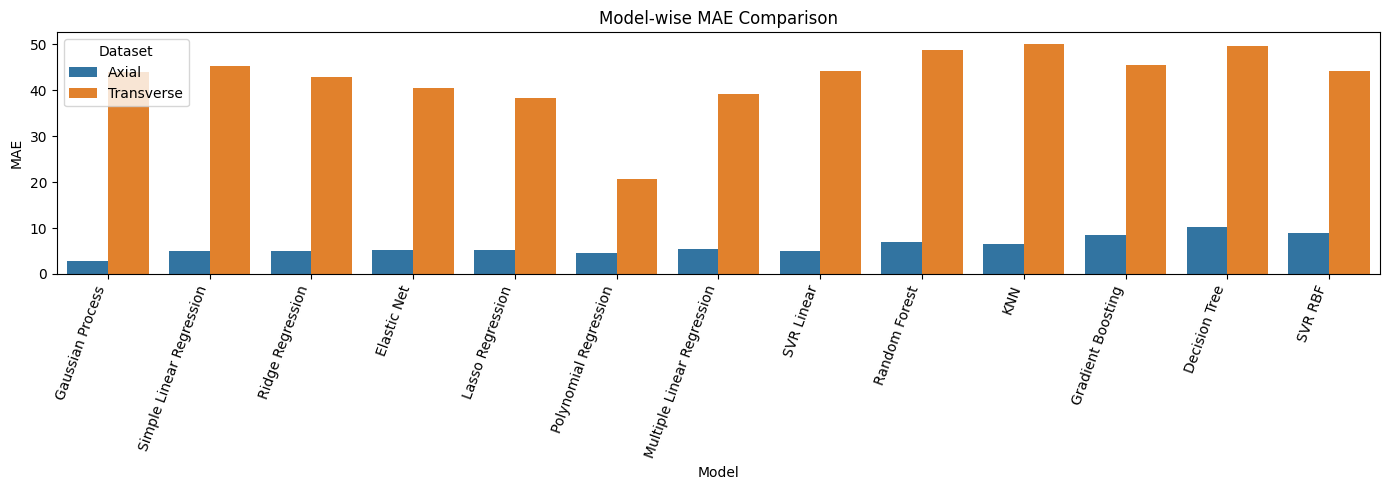

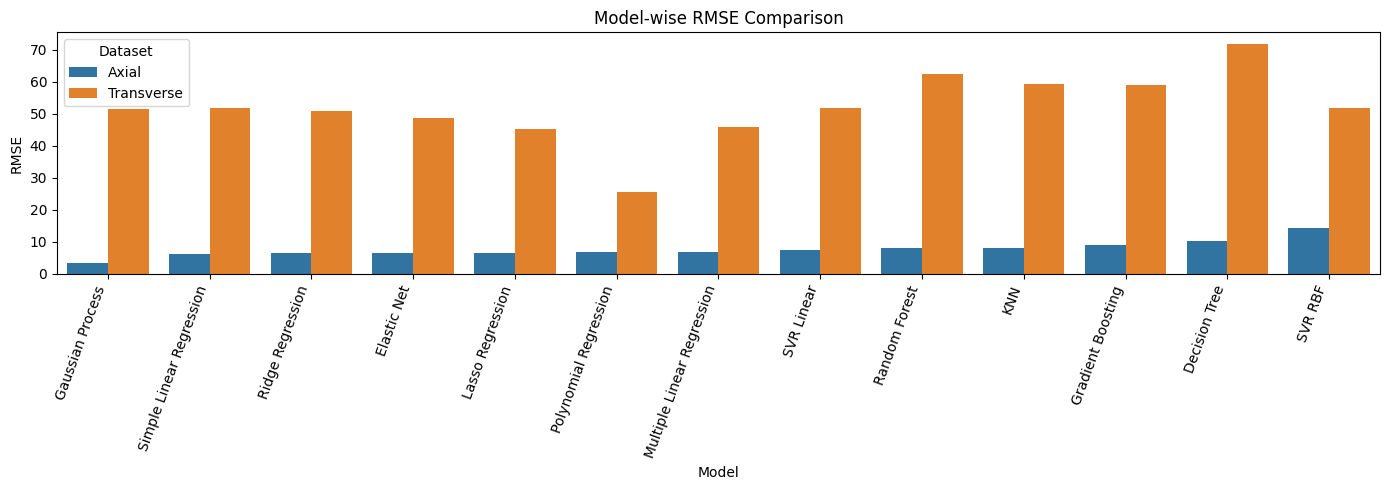

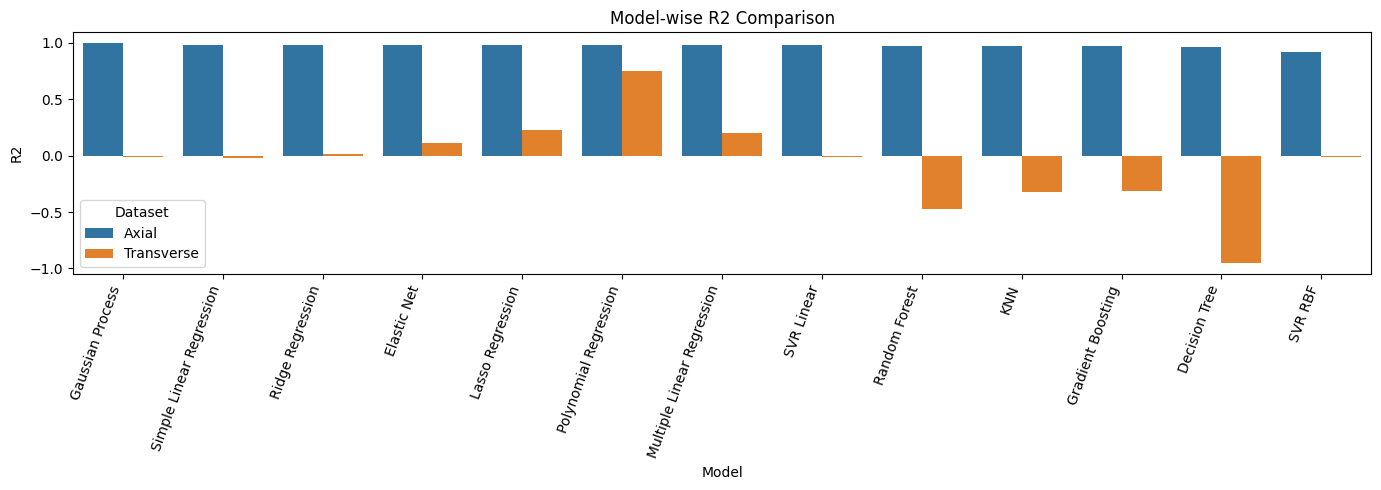

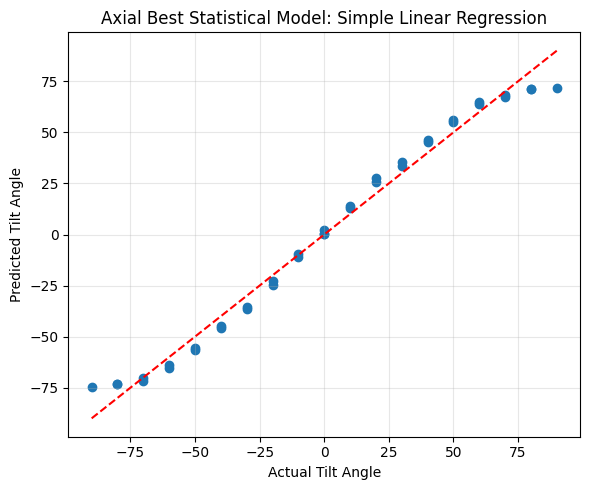

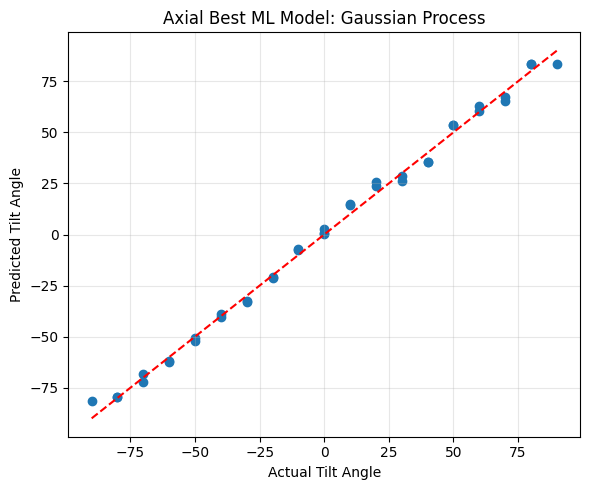

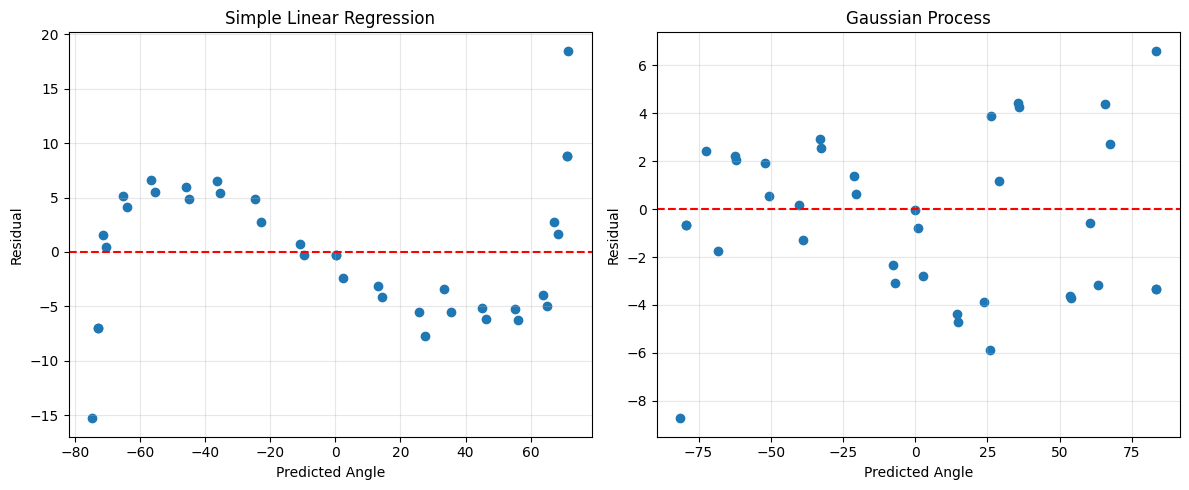

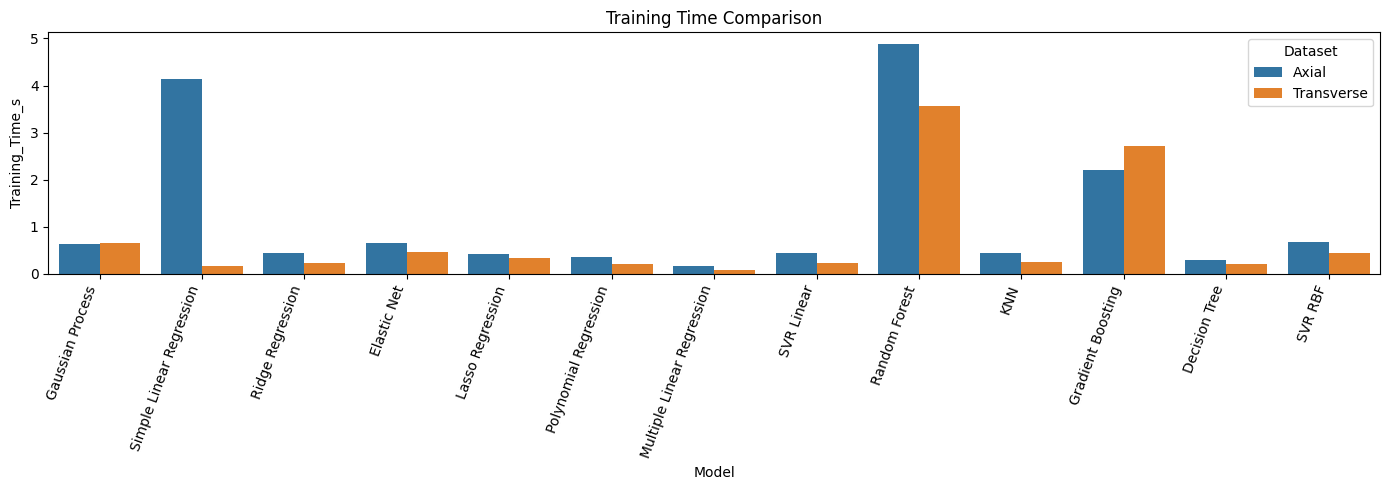


Best axial model: Gaussian Process
Best transverse model: Polynomial Regression


In [ ]:
## TASK-6

from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.base import clone

# Define all statistical and ML models
model_specs = {
    "Simple Linear Regression": (
        ["Differential_Change"],
        Pipeline([("scale", StandardScaler()),
                  ("model", LinearRegression())]),
        {}
    ),
    "Multiple Linear Regression": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("model", LinearRegression())]),
        {}
    ),
    "Polynomial Regression": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([
            ("poly", PolynomialFeatures(include_bias=False)),
            ("scale", StandardScaler()),
            ("model", LinearRegression())
        ]),
        {"poly__degree": [2, 3]}
    ),
    "Ridge Regression": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("scale", StandardScaler()),
                  ("model", Ridge())]),
        {"model__alpha": [0.1, 1, 10]}
    ),
    "Lasso Regression": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("scale", StandardScaler()),
                  ("model", Lasso(max_iter=10000))]),
        {"model__alpha": [0.001, 0.01, 0.1]}
    ),
    "Elastic Net": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("scale", StandardScaler()),
                  ("model", ElasticNet(max_iter=10000))]),
        {"model__alpha": [0.01, 0.1],
         "model__l1_ratio": [0.2, 0.5, 0.8]}
    ),
    "SVR Linear": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("scale", StandardScaler()),
                  ("model", SVR(kernel="linear"))]),
        {"model__C": [0.1, 1, 10]}
    ),
    "SVR RBF": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("scale", StandardScaler()),
                  ("model", SVR(kernel="rbf"))]),
        {"model__C": [0.1, 1, 10],
         "model__gamma": ["scale", "auto"]}
    ),
    "Decision Tree": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("model", DecisionTreeRegressor(random_state=42))]),
        {"model__max_depth": [2, 3, 5]}
    ),
    "Random Forest": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("model", RandomForestRegressor(random_state=42))]),
        {"model__n_estimators": [50, 100]}
    ),
    "KNN": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("scale", StandardScaler()),
                  ("model", KNeighborsRegressor())]),
        {"model__n_neighbors": [3, 5, 7]}
    ),
    "Gradient Boosting": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([("model", GradientBoostingRegressor(random_state=42))]),
        {"model__learning_rate": [0.01, 0.1]}
    ),
    "Gaussian Process": (
        ["Delta_FBG1", "Delta_FBG2"],
        Pipeline([
            ("scale", StandardScaler()),
            ("model", GaussianProcessRegressor(
                normalize_y=True, random_state=42
            ))
        ]),
        {"model__kernel": [RBF(), Matern()]}
    )
}

def evaluate_models(data, name):
    groups = data["Tilt_Angle"].to_numpy()
    outer_cv = GroupKFold(n_splits=5)
    results = []
    predictions = {}
    best_params = {}

    for model_name, (features, estimator, params) in model_specs.items():
        X = data[features].to_numpy()
        y = data["Tilt_Angle"].to_numpy()
        oof_pred = np.full(len(y), np.nan)
        total_time = 0

        for train_idx, test_idx in outer_cv.split(X, y, groups):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train = y[train_idx]
            train_groups = groups[train_idx]

            # Tune hyperparameters only within the training fold
            inner_cv = GroupKFold(n_splits=3)
            search = GridSearchCV(
                clone(estimator),
                params if params else [{}],
                scoring="neg_root_mean_squared_error",
                cv=inner_cv,
                n_jobs=-1
            )

            start = time.time()
            search.fit(
                X_train, y_train,
                groups=train_groups
            )
            total_time += time.time() - start
            oof_pred[test_idx] = search.predict(X_test)

            best_params[model_name] = search.best_params_

        predictions[model_name] = oof_pred

        results.append({
            "Model": model_name,
            "MAE": mean_absolute_error(y, oof_pred),
            "MSE": mean_squared_error(y, oof_pred),
            "RMSE": np.sqrt(mean_squared_error(y, oof_pred)),
            "R2": r2_score(y, oof_pred),
            "Training_Time_s": total_time
        })

    result_df = pd.DataFrame(results).sort_values("RMSE")

    print("\n", name, "FIVE-FOLD GROUPED CV RESULTS")
    print(result_df.round(4).to_string(index=False))

    print("\nSelected hyperparameters:")
    for model_name, params in best_params.items():
        print(model_name, ":", params)

    return result_df, predictions, data["Tilt_Angle"].to_numpy()


# Evaluate axial and transverse data separately
axial_cv_results, axial_cv_predictions, axial_actual = evaluate_models(
    axial, "AXIAL"
)

transverse_cv_results, transverse_cv_predictions, transverse_actual = evaluate_models(
    transverse, "TRANSVERSE"
)


# Plot 1: MAE comparison
def plot_metric(axial_results, transverse_results, metric, title):
    combined = pd.concat([
        axial_results.assign(Dataset="Axial"),
        transverse_results.assign(Dataset="Transverse")
    ])

    plt.figure(figsize=(14, 5))
    sns.barplot(data=combined, x="Model", y=metric, hue="Dataset")
    plt.title(title)
    plt.xticks(rotation=70, ha="right")
    plt.tight_layout()
    plt.show()

plot_metric(axial_cv_results, transverse_cv_results,
            "MAE", "Model-wise MAE Comparison")

# Plot 2: RMSE comparison
plot_metric(axial_cv_results, transverse_cv_results,
            "RMSE", "Model-wise RMSE Comparison")

# Plot 3: R2 comparison
plot_metric(axial_cv_results, transverse_cv_results,
            "R2", "Model-wise R2 Comparison")


# Select the best statistical and conventional ML models
statistical_names = [
    "Simple Linear Regression",
    "Multiple Linear Regression",
    "Polynomial Regression",
    "Ridge Regression",
    "Lasso Regression",
    "Elastic Net"
]

ml_names = [
    "SVR Linear", "SVR RBF", "Decision Tree",
    "Random Forest", "KNN", "Gradient Boosting",
    "Gaussian Process"
]

def plot_actual_predicted(results, predictions, actual, allowed, name):
    candidates = results[results["Model"].isin(allowed)]
    best_name = candidates.iloc[0]["Model"]
    pred = predictions[best_name]

    plt.figure(figsize=(6, 5))
    plt.scatter(actual, pred)
    low = min(actual.min(), pred.min())
    high = max(actual.max(), pred.max())
    plt.plot([low, high], [low, high], "r--")
    plt.xlabel("Actual Tilt Angle")
    plt.ylabel("Predicted Tilt Angle")
    plt.title(name + ": " + best_name)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return best_name

# Plots 4 and 5: Best statistical and ML models for axial data
best_axial_stat = plot_actual_predicted(
    axial_cv_results, axial_cv_predictions,
    axial_actual, statistical_names, "Axial Best Statistical Model"
)

best_axial_ml = plot_actual_predicted(
    axial_cv_results, axial_cv_predictions,
    axial_actual, ml_names, "Axial Best ML Model"
)


# Plot 6: Residual plots for the selected axial models
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model_name in zip(
    axes, [best_axial_stat, best_axial_ml]
):
    pred = axial_cv_predictions[model_name]
    residual = axial_actual - pred
    ax.scatter(pred, residual)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted Angle")
    ax.set_ylabel("Residual")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Plot 7: Training time comparison
plot_metric(axial_cv_results, transverse_cv_results,
            "Training_Time_s", "Training Time Comparison")


print("\nBest axial model:", axial_cv_results.iloc[0]["Model"])
print("Best transverse model:", transverse_cv_results.iloc[0]["Model"])


   Dataset Noise_Level     MAE       MSE    RMSE      R2
     Axial          0%  5.3583   46.5443  6.8223  0.9824
     Axial          1%  5.3935   47.4706  6.8899  0.9820
     Axial          5%  6.1464   62.0617  7.8779  0.9765
     Axial         10%  6.7705   98.9140  9.9456  0.9626
Transverse          0% 39.0920 2110.9139 45.9447  0.2014
Transverse          1% 39.7700 2176.7486 46.6556  0.1765
Transverse          5% 48.6483 3462.2876 58.8412 -0.3099
Transverse         10% 71.7382 7085.8240 84.1773 -1.6807


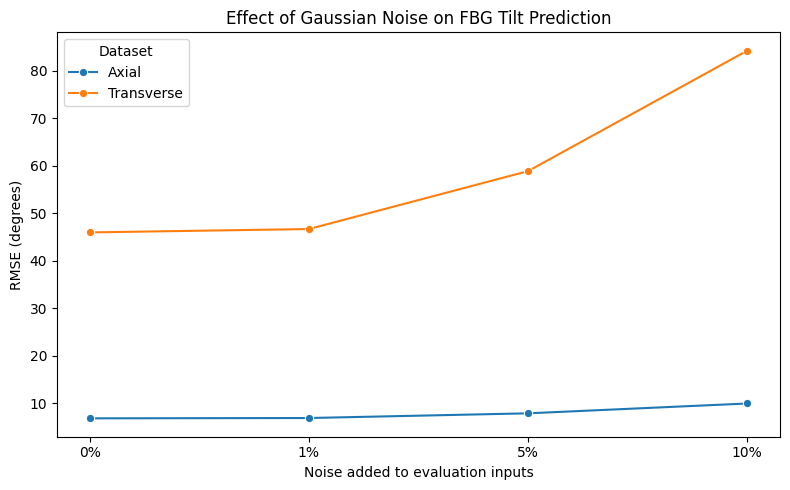

In [ ]:

# Task A: Noise Robustness

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

noise_levels = [0, 0.01, 0.05, 0.10]
results = []
rng = np.random.default_rng(42)

for name, data in [("Axial", axial), ("Transverse", transverse)]:
    X = data[["Delta_FBG1", "Delta_FBG2"]].to_numpy(dtype=float)
    y = data["Tilt_Angle"].to_numpy()
    groups = data["Tilt_Angle"].to_numpy()

    for noise in noise_levels:
        predictions = np.zeros(len(y))
        cv = GroupKFold(n_splits=5)

        for train_idx, test_idx in cv.split(X, y, groups):
            model = make_pipeline(StandardScaler(), LinearRegression())
            model.fit(X[train_idx], y[train_idx])

            # Add Gaussian noise only to evaluation inputs
            X_test = X[test_idx].copy()
            noise_std = X[train_idx].std(axis=0)
            X_test += rng.normal(
                0, noise * noise_std, size=X_test.shape
            )
            predictions[test_idx] = model.predict(X_test)

        results.append({
            "Dataset": name,
            "Noise_Level": f"{noise * 100:.0f}%",
            "MAE": mean_absolute_error(y, predictions),
            "MSE": mean_squared_error(y, predictions),
            "RMSE": np.sqrt(mean_squared_error(y, predictions)),
            "R2": r2_score(y, predictions)
        })

noise_results = pd.DataFrame(results)
print(noise_results.round(4).to_string(index=False))

# Compare RMSE at different noise levels
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=noise_results,
    x="Noise_Level",
    y="RMSE",
    hue="Dataset",
    marker="o"
)
plt.title("Effect of Gaussian Noise on FBG Tilt Prediction")
plt.xlabel("Noise added to evaluation inputs")
plt.ylabel("RMSE (degrees)")
plt.tight_layout()
plt.show()
